# Lesson 1 — Flow basics: squishing a ball of Play-Doh

**Goal:** see every moving part of a normalizing flow on a problem small enough to check by hand.

We will:
1. Make a 2D "target" shape whose true density we know exactly (so we can grade the flow).
2. Build a flow with `normflows`: a base distribution (the dice / Play-Doh ball) plus a stack of layers (the squishing steps).
3. Train it with **Recipe A** (`forward_kld`): we have example points and make them as likely as possible.
4. Watch the dice get squished layer by layer.
5. Run five checks that prove the flow does what we claimed in conversation:
   - **A.** It really is invertible: `inverse(forward(z)) == z`.
   - **B.** Each layer's `log_det` really is the log-stretch of space (compared against autograd's Jacobian).
   - **C.** The learned density is a real density: it integrates to 1.
   - **D.** Points have probability 0, but *regions* have real probabilities — and counting samples gets them right.
   - **E.** Density numbers depend on units; region probabilities don't.

Everything here runs on CPU in about a minute.

In [1]:
import sys, time
from pathlib import Path

# Use the normflows code from this repo checkout (the folder above geo/)
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import torch
import torch.distributions as D
import matplotlib.pyplot as plt
import normflows as nf

torch.manual_seed(0)
np.random.seed(0)
torch.set_default_dtype(torch.float64)  # double precision keeps the numerical checks clean
print("normflows loaded from:", nf.__file__)

normflows loaded from: C:\Users\jeffe\OneDrive\Documents\ExploreTech\normalizing-flows\.claude\worktrees\steady-finding-stearns\normflows\__init__.py


## 1. The target: a shape we know exactly

A mixture of three tilted Gaussian blobs with unequal weights (25% / 45% / 30%).
Because it's built from Gaussians, we can compute its **exact** density and exact region probabilities — that's our answer key.

In the geophysics lessons, the "target" will be *the pile of undergrounds consistent with the readings*. Here it's just a shape.

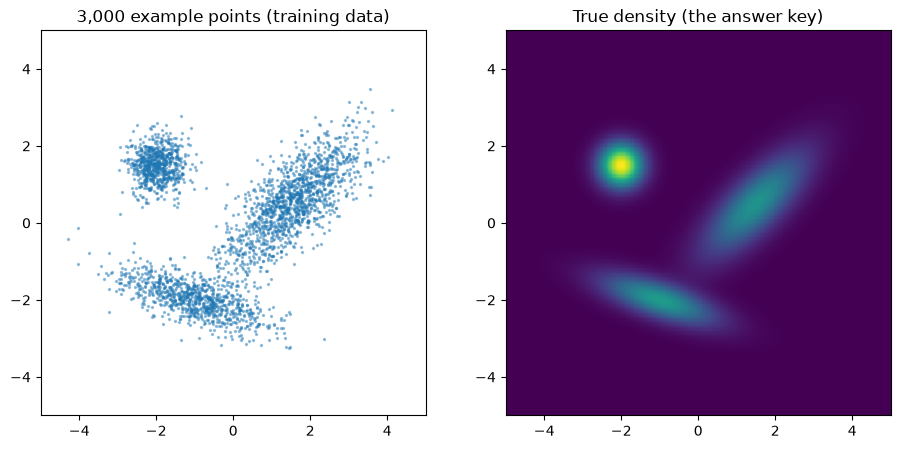

In [2]:
weights = torch.tensor([0.25, 0.45, 0.30])
means = torch.tensor([[-2.0, 1.5], [1.5, 0.5], [-1.0, -2.0]])
covs = torch.tensor([
    [[0.15, 0.00], [0.00, 0.15]],   # small round blob
    [[0.80, 0.60], [0.60, 0.80]],   # long diagonal blob
    [[1.00, -0.30], [-0.30, 0.20]], # flat tilted blob
])
target = D.MixtureSameFamily(D.Categorical(weights), D.MultivariateNormal(means, covs))

x_train = target.sample((20000,))
x_test = target.sample((20000,))  # held out: only used for grading

# Grid for density pictures
lim = 5
n_grid = 300
g = torch.linspace(-lim, lim, n_grid)
gx, gy = torch.meshgrid(g, g, indexing="xy")
grid = torch.stack([gx.reshape(-1), gy.reshape(-1)], dim=1)
cell_area = (g[1] - g[0]) ** 2
p_true_grid = target.log_prob(grid).exp().reshape(n_grid, n_grid)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].scatter(*x_train[:3000].T, s=2, alpha=0.4)
ax[0].set_title("3,000 example points (training data)")
ax[1].pcolormesh(gx, gy, p_true_grid, shading="auto")
ax[1].set_title("True density (the answer key)")
for a in ax:
    a.set_aspect("equal"); a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
plt.show()

## 2. Build the flow

- **Base distribution `q0`** — the dice. A 2D Gaussian (`DiagGaussian`).
- **Layers** — 8 *affine coupling blocks* (the Real NVP design). Each block:
  splits the point into two halves `(a, b)`, keeps `a` fixed, and stretches+shifts `b` by amounts that a small neural network computes **from `a`**.
  That's why it's invertible (you can always recompute the stretch from `a`, which didn't change) and why `log_det` is cheap (it's just the sum of log-stretches).
- Between blocks a `Permute` swaps the halves so both coordinates get transformed.

In [3]:
def make_flow(n_blocks=8, hidden=64):
    flows = []
    for _ in range(n_blocks):
        # maps the fixed half (1 number) to shift and log-scale for the other half (2 numbers)
        param_map = nf.nets.MLP([1, hidden, hidden, 2], init_zeros=True)
        flows.append(nf.flows.AffineCouplingBlock(param_map))
        flows.append(nf.flows.Permute(2, mode="swap"))
    q0 = nf.distributions.DiagGaussian(2)
    return nf.NormalizingFlow(q0=q0, flows=flows)

model = make_flow()
print(f"{len(model.flows)} flow layers, {sum(p.numel() for p in model.parameters()):,} trainable numbers")

16 flow layers, 35,348 trainable numbers


`init_zeros=True` makes every layer start as the identity (no squishing), so before training the flow is just the dice.

## 3. Train with Recipe A (`forward_kld`)

Each step: take a batch of real points, run them **backwards** through the layers to the dice,
compute `log q(x) = log q0(z) + Σ log_det`, and push that up. The loss is `-mean(log q(x))`.

**Built-in grading:** the best possible loss equals the target's *entropy* `H = -E[log p_true(x)]`, which we can compute because we know `p_true`.
The gap `loss − H` is exactly the KL divergence between truth and flow, so it should shrink toward 0.

Best possible loss (entropy of the target): 2.7949


step  1000  loss 2.8080


step  2000  loss 2.8014


step  3000  loss 2.7979


step  4000  loss 2.7956
trained in 40.3s


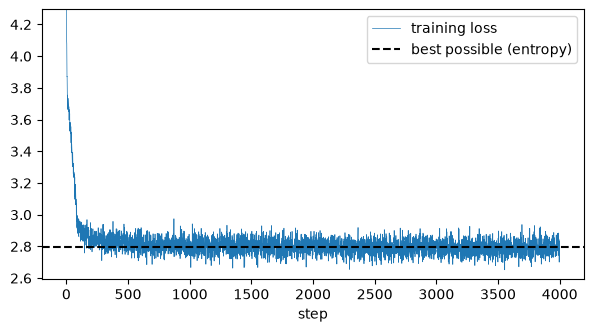

In [4]:
H_true = -target.log_prob(x_test).mean().item()
print(f"Best possible loss (entropy of the target): {H_true:.4f}")

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=4000)
losses = []
t0 = time.time()
for it in range(4000):
    idx = torch.randint(0, len(x_train), (512,))
    loss = model.forward_kld(x_train[idx])
    optimizer.zero_grad()
    if torch.isfinite(loss):  # the library examples' safety check
        loss.backward()
        optimizer.step()
    scheduler.step()
    losses.append(loss.item())
    if (it + 1) % 1000 == 0:
        print(f"step {it+1:5d}  loss {np.mean(losses[-100:]):.4f}")
print(f"trained in {time.time()-t0:.1f}s")

plt.figure(figsize=(7, 3.5))
plt.plot(losses, lw=0.5, label="training loss")
plt.axhline(H_true, color="k", ls="--", label="best possible (entropy)")
plt.ylim(H_true - 0.2, H_true + 1.5); plt.xlabel("step"); plt.legend(); plt.show()

## 4. Did it learn the shape?

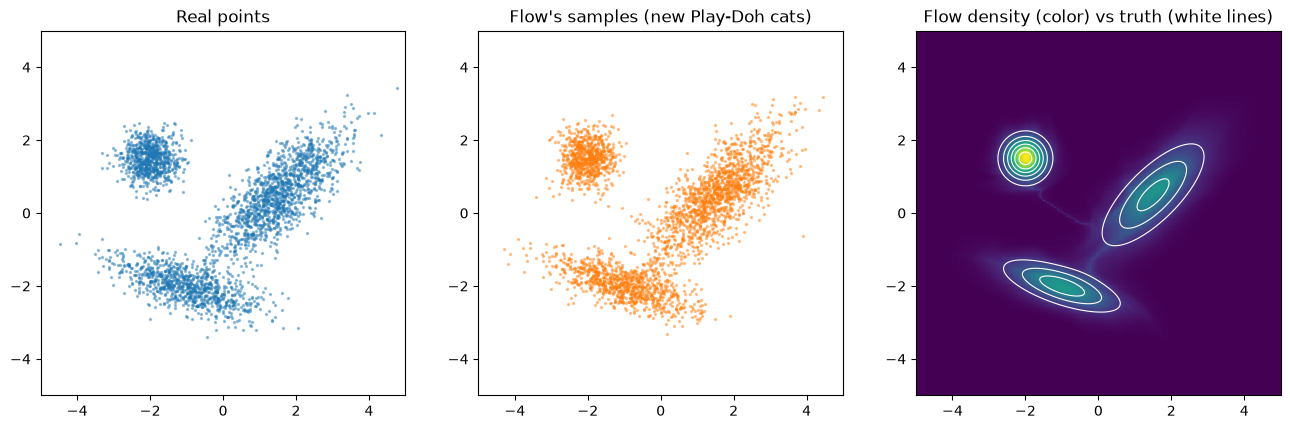

In [5]:
model.eval()
with torch.no_grad():
    x_flow, _ = model.sample(3000)
    p_flow_grid = model.log_prob(grid).exp().reshape(n_grid, n_grid)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].scatter(*x_test[:3000].T, s=2, alpha=0.4); ax[0].set_title("Real points")
ax[1].scatter(*x_flow.T, s=2, alpha=0.4, color="C1"); ax[1].set_title("Flow's samples (new Play-Doh cats)")
ax[2].pcolormesh(gx, gy, p_flow_grid, shading="auto")
ax[2].contour(gx, gy, p_true_grid, levels=6, colors="w", linewidths=0.8)
ax[2].set_title("Flow density (color) vs truth (white lines)")
for a in ax:
    a.set_aspect("equal"); a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
plt.show()

## 5. Watch the squishing, layer by layer

Roll 4,000 dice, color each by its starting angle, and plot it after every coupling block.
The colors let you track which part of the ball ends up in which blob.

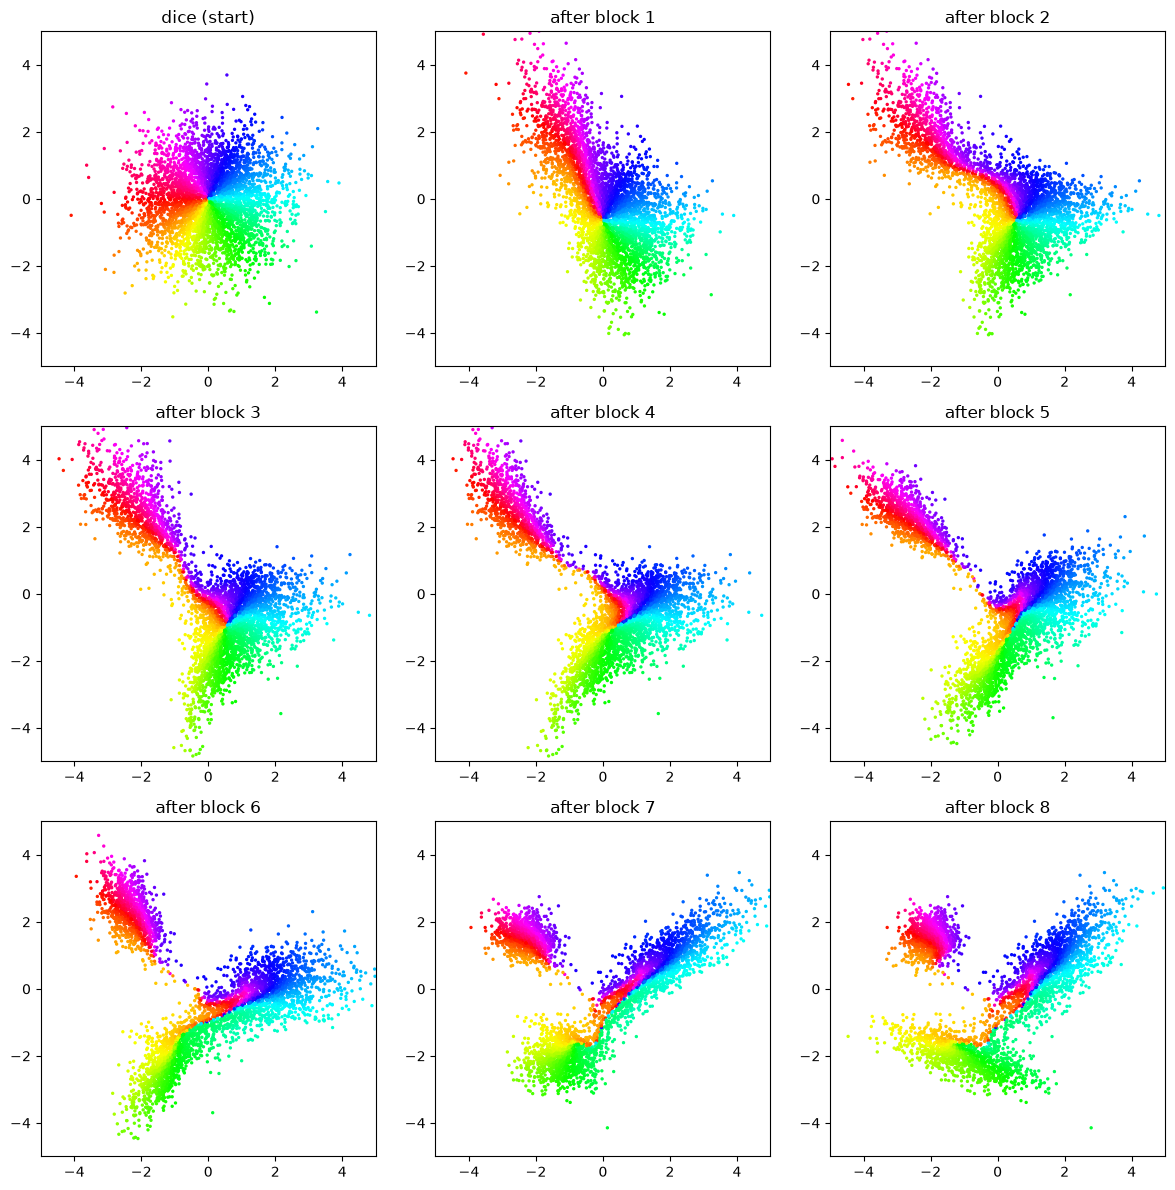

In [6]:
with torch.no_grad():
    z, _ = model.q0(4000)
    color = torch.atan2(z[:, 1], z[:, 0]).numpy()
    snapshots = [("dice (start)", z.clone())]
    for i, layer in enumerate(model.flows):
        z, _ = layer(z)
        if isinstance(layer, nf.flows.Permute):  # snapshot after each block (+ its swap)
            snapshots.append((f"after block {(i+1)//2}", z.clone()))

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for a, (title, pts) in zip(axes.flat, snapshots):
    pts = pts.clone()
    if title != "dice (start)" and ((int(title.split()[-1])) % 2 == 1):
        pts = pts[:, [1, 0]]  # undo the pending swap so every panel shows (x0, x1) the same way round
    a.scatter(*pts.T, c=color, cmap="hsv", s=2)
    a.set_title(title); a.set_aspect("equal"); a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
plt.tight_layout(); plt.show()

**Notice the thin bridges between blobs** (also faintly visible in the density plot above).
A flow is a smooth, invertible squish of *one connected ball*, so it can never tear the Play-Doh into separate pieces —
it can only stretch the connecting strands very thin. More layers make the strands thinner, but never zero.

This matters for geophysics: if two very different undergrounds both fit the readings (two separate "islands" of answers),
the flow will put a little probability on the in-between undergrounds too. Keep it in mind when reading results in Lessons 2–4.

## 6. The checks

### Check A — it really is invertible
Push dice forward, then run backward. We should get the dice back to near machine precision.

In [7]:
with torch.no_grad():
    z0, _ = model.q0(5000)
    x = model.forward(z0)
    z_back = model.inverse(x)
inv_err = (z_back - z0).abs().max().item()
print(f"max |inverse(forward(z)) - z| = {inv_err:.2e}")

max |inverse(forward(z)) - z| = 1.69e-14


### Check B — `log_det` is the log of how much space got stretched
For a few points, ask autograd for the full 2×2 Jacobian of the whole flow, take `log|det|`,
and compare to the `log_det` the layers reported. This is the change-of-variables formula, checked directly.

In [8]:
z_pts, _ = model.q0(8)
_, log_det_reported = model.forward_and_log_det(z_pts)
log_det_autograd = torch.stack([
    torch.linalg.slogdet(torch.autograd.functional.jacobian(lambda v: model.forward(v[None])[0], zi))[1]
    for zi in z_pts
])
jac_err = (log_det_reported - log_det_autograd).abs().max().item()
for r, a in zip(log_det_reported[:4], log_det_autograd[:4]):
    print(f"reported {r.item():+.6f}   autograd {a.item():+.6f}")
print(f"max difference over 8 points: {jac_err:.2e}")

reported +0.706822   autograd +0.706822
reported +0.233848   autograd +0.233848
reported +0.423611   autograd +0.423611
reported +0.279909   autograd +0.279909
max difference over 8 points: 1.55e-15


### Check C — it's a real density (adds up to 1)
Add up `density × cell area` over the grid. For any proper density this is ≈ 1 (a tiny bit leaks outside the grid).

In [9]:
mass_flow = (p_flow_grid.sum() * cell_area).item()
mass_true = (p_true_grid.sum() * cell_area).item()
print(f"flow density adds up to {mass_flow:.4f}   (truth on same grid: {mass_true:.4f})")

flow density adds up to 1.0000   (truth on same grid: 1.0000)


### Check D — points vs regions

**A single point has probability 0.** Its *density* is a finite number (how crowded things are there), and density can even exceed 1.
**A region has a real probability**, which we can get two ways: add up density over it, or simply **count samples** that land in it.
The counting approach is what the drill-hole decisions in later lessons use.

In [10]:
pt = torch.tensor([[-2.0, 1.5]])  # centre of the small blob
with torch.no_grad():
    print(f"density at {pt.tolist()[0]}:  flow {model.log_prob(pt).exp().item():.3f}   truth {target.log_prob(pt).exp().item():.3f}   (a density, not a probability)")

# Region: left half-plane x0 < 0. Exact answer: each blob's x0-marginal is a 1D Gaussian.
norm = D.Normal(0.0, 1.0)
p_exact = (weights * norm.cdf((0 - means[:, 0]) / covs[:, 0, 0].sqrt())).sum().item()
with torch.no_grad():
    xs, _ = model.sample(200000)
p_count = (xs[:, 0] < 0).double().mean().item()
p_integrate = (p_flow_grid[:, g < 0].sum() * cell_area).item()  # columns are x0 (indexing='xy')
print(f"\nP(x0 < 0):  exact {p_exact:.4f}   flow by counting samples {p_count:.4f}   flow by adding up density {p_integrate:.4f}")

# A second region: inside the circle of radius 1 around (1.5, 0.5)
in_disk = lambda p: ((p - torch.tensor([1.5, 0.5])) ** 2).sum(1) < 1.0
big_truth = target.sample((1_000_000,))
p_disk_truth = in_disk(big_truth).double().mean().item()
p_disk_flow = in_disk(xs).double().mean().item()
print(f"P(inside disk):  truth {p_disk_truth:.4f} (1M exact samples)   flow {p_disk_flow:.4f}")

density at [-2.0, 1.5]:  flow 0.272   truth 0.265   (a density, not a probability)



P(x0 < 0):  exact 0.5234   flow by counting samples 0.5289   flow by adding up density 0.5298
P(inside disk):  truth 0.2422 (1M exact samples)   flow 0.2381


### Check E — density depends on units, region probability doesn't
Pretend the coordinates were in kilometres and switch to metres (`y = 1000·x`). That's a stretch by 1000 in each of 2 directions,
so density drops by 1000² = 10⁶ — but the probability of "the left half" is unchanged, because it's the same set of outcomes.

In [11]:
with torch.no_grad():
    dens_km = model.log_prob(pt).exp().item()
    dens_m = dens_km / 1000**2          # change of variables: divide by |det| = 1e6
    p_count_m = ((xs * 1000)[:, 0] < 0).double().mean().item()
print(f"density at the point: {dens_km:.3e} per km²  =  {dens_m:.3e} per m²")
print(f"P(left half): {p_count:.4f} in km,  {p_count_m:.4f} in m  (identical)")

density at the point: 2.719e-01 per km²  =  2.719e-07 per m²
P(left half): 0.5289 in km,  0.5289 in m  (identical)


### Grade: KL divergence on held-out data
`KL(truth ‖ flow) = E[log p_true − log q_flow]` on points the flow never saw. 0 means perfect; it's measured in "nats".

In [12]:
with torch.no_grad():
    kl = (target.log_prob(x_test) - model.log_prob(x_test)).mean().item()
print(f"KL(truth || flow) on held-out points: {kl:.4f} nats")

KL(truth || flow) on held-out points: 0.0101 nats


## Report card
These asserts make the notebook fail loudly if any check breaks (e.g. after you change the model).

In [13]:
results = {
    "A invertible (max error < 1e-8)": inv_err < 1e-8,
    "B log_det matches autograd (< 1e-8)": jac_err < 1e-8,
    "C density adds to ~1 (within 0.01 of truth)": abs(mass_flow - mass_true) < 0.01,
    "D region prob by counting within 0.01": abs(p_count - p_exact) < 0.01,
    "D region prob by integrating within 0.01": abs(p_integrate - p_exact) < 0.01,
    "D disk prob within 0.01": abs(p_disk_flow - p_disk_truth) < 0.01,
    "E unit change leaves region prob unchanged": p_count == p_count_m,
    "fit quality: held-out KL < 0.05 nats": kl < 0.05,
}
for k, v in results.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(results.values()), "some checks failed"

PASS  A invertible (max error < 1e-8)
PASS  B log_det matches autograd (< 1e-8)
PASS  C density adds to ~1 (within 0.01 of truth)
PASS  D region prob by counting within 0.01
PASS  D region prob by integrating within 0.01
PASS  D disk prob within 0.01
PASS  E unit change leaves region prob unchanged
PASS  fit quality: held-out KL < 0.05 nats


## Things to try
- Set `n_blocks=2` in `make_flow` and retrain: the blobs get blurrier and the KL grade rises. Fewer squishing steps = less flexible Play-Doh.
- Delete the `Permute` layers: only one coordinate ever gets transformed. What happens?
- Change the mixture weights and check that Check D still tracks the exact answer.
- Move the blobs further apart and watch the bridges: does the KL grade get worse?

**Next lesson:** we swap "example points" for a **physics score** — a buried magnetic body and the readings it would produce — and train with Recipe B.